# 03 Airport network (RQ2)
Do airports form communities, and which airports connect the network? We build the graph from the clean data (January–June, all scheduled flights) and then compare delays between communities.

**Before running:** run notebook 01c first, because it creates the edge table used here. Select the "Python (ctds)" kernel and run the notebook from the `notebooks/` folder (see the README).

In [ ]:
# imports
import sys
sys.path.append("..")  # import the src/ folder from the project root

import airportsdata
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from networkx.algorithms.community import louvain_communities, modularity
from scipy.stats import kruskal, spearmanr
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score

from src.config import CLEAN_PARQUET, EDGES_PARQUET, FIGURES_DIR, TABLES_DIR, RANDOM_SEED
from src.data_loading import load_flights
from src.network import best_louvain, build_edges, build_graph
from src.profiling import track

In [2]:
# settings
pd.set_option("display.float_format", "{:,.3f}".format)


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"03_{name}.png", dpi=150)
    plt.show()


# give every airport the number of its community, in the order of airport_list
def community_labels(communities, airport_list):
    community_of_airport = {}
    for number, community in enumerate(communities):
        for airport in community:
            community_of_airport[airport] = number
    return np.array([community_of_airport[airport] for airport in airport_list])


# the opposite: a list of sets of airports, one set per label
def groups_from_labels(labels, airport_list):
    airport_array = np.array(airport_list)
    return [set(airport_array[labels == label]) for label in np.unique(labels)]

## 1. Build the graph
Each airport is a node and each pair of airports with direct flights is one edge (A→B and B→A together), weighted by the number of flights in both directions. For betweenness we use distance = 1 / flights (not the distance in miles), so busy routes count as short.

In [3]:
# build the undirected graph from the January-June edge table
edges = pd.read_parquet(EDGES_PARQUET)
graph = build_graph(edges)

# same airport order everywhere
airport_list = sorted(graph)


# total flights and number of connected airports per airport
flights_per_airport = dict(graph.degree(weight="flights"))
degrees = []
for airport, degree in graph.degree():
    degrees.append(degree)

print("Airports:", graph.number_of_nodes())
print("Edges:", graph.number_of_edges())
print("Connected:", nx.is_connected(graph))
print("Density:", round(nx.density(graph), 3))
print("Median degree:", round(np.median(degrees)))


# betweenness and the community comparison need one connected network
assert nx.is_connected(graph), "the airport graph is not connected"

Airports: 343
Edges: 3284
Connected: True
Density: 0.056
Median degree: 6


## 2. Degree distribution
Share of airports with at least k connections, on a log-log scale. A long tail means a few big hubs and many small airports.

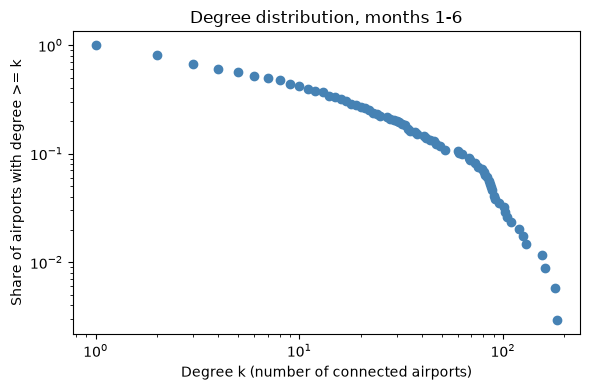

Airports with degree >= 100: 11
Airports with degree <= 3: 136


In [4]:
# share of airports with at least k connections
degree_values = np.array(degrees)
unique_degrees = np.unique(degree_values)
share_at_least = []
for k in unique_degrees:
    share_at_least.append(np.mean(degree_values >= k))


fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(unique_degrees, share_at_least, marker="o", linestyle="none", color="steelblue")
ax.set_xlabel("Degree k (number of connected airports)")
ax.set_ylabel("Share of airports with degree >= k")
ax.set_title("Degree distribution, months 1-6")
save_fig(fig, "degree_distribution")

print("Airports with degree >= 100:", int(np.sum(degree_values >= 100)))
print("Airports with degree <= 3:", int(np.sum(degree_values <= 3)))

11 airports connect to 100 or more others, while 136 (40%) have three connections or fewer: a few hubs and many small airports, the usual hub-and-spoke structure.

## 3. Louvain communities
Louvain groups airports so that most flights stay inside a group, which it measures with modularity. We first check the resolution: higher values give more, smaller communities. The result also depends on the random seed, so we run 20 seeds and keep the run with the highest modularity.

In [5]:
# try a few resolutions
resolution_rows = []
for resolution in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    communities = louvain_communities(graph, weight="flights", resolution=resolution, seed=RANDOM_SEED)
    score = modularity(graph, communities, weight="flights")
    resolution_rows.append({"resolution": resolution, "communities": len(communities), "modularity": score})

display(pd.DataFrame(resolution_rows))

,resolution,communities,modularity
0,0.500,2,0.022
1,0.750,2,0.235
2,1.000,5,0.253
3,1.250,7,0.234
4,1.500,10,0.202
5,2.000,17,0.153


In [6]:
# run Louvain with 20 seeds
with track("louvain_20_seeds", airports=graph.number_of_nodes()):
    all_runs = []
    for seed in range(20):
        all_runs.append(louvain_communities(graph, weight="flights", seed=seed))

modularities = []
for communities in all_runs:
    modularities.append(modularity(graph, communities, weight="flights"))


# keep the best run, community 0 = largest
best_run = sorted(all_runs[int(np.argmax(modularities))], key=len, reverse=True)
louvain = community_labels(best_run, airport_list)


# compare every run with the best one
seed_rows = []
for seed, communities in enumerate(all_runs):
    seed_rows.append({
        "seed": seed,
        "communities": len(communities),
        "modularity": modularities[seed],
        "ARI_vs_best": adjusted_rand_score(louvain, community_labels(communities, airport_list)),
    })
seed_table = pd.DataFrame(seed_rows)
display(seed_table.drop(columns="seed").describe().loc[["mean", "min", "max"]])

print("Number of communities:", len(best_run))
print("Modularity:", round(max(modularities), 3))

[louvain_20_seeds] runtime: 3.08 s | peak memory (Python/pandas): 1.6 MB | peak memory (pyarrow pool): 0.3 MB


,communities,modularity,ARI_vs_best
mean,4.350,0.254,0.847
min,4.000,0.250,0.645
max,6.000,0.256,1.000


Number of communities: 4
Modularity: 0.256


We keep the default resolution of 1. Modularity is always measured at resolution 1 here, so it tends to peak there and does not justify the choice on its own; the sweep also uses a single seed, which is why it shows 5 communities at resolution 1 while the best of 20 seeds has 4. Lower resolutions give only 2 communities and higher ones split the network into 7 to 17, while resolution 1 gives a few regional communities that are easy to interpret. Over 20 seeds Louvain finds 4 to 6 communities, and the best run has 4, with modularity 0.256, a moderate community structure. The runs mostly agree with the best one (mean ARI 0.85, lowest 0.65), so the main communities depend little on the seed, even though some runs split them differently.

In [ ]:
# does a longer search find a better partition? same procedure with 100 seeds
best_100, modularity_100 = best_louvain(graph, n_seeds=100)
labels_100 = community_labels(best_100, airport_list)

print("Best of 20 seeds: ", len(best_run), "communities | modularity", round(max(modularities), 4))
print("Best of 100 seeds:", len(best_100), "communities | modularity", round(modularity_100, 4))
print("ARI, best of 100 vs best of 20:", round(adjusted_rand_score(louvain, labels_100), 3))

With 100 seeds the best partition has a slightly higher modularity (0.257 against 0.256) but the same four communities, and it agrees closely with ours (ARI 0.93): only a few small airports move between the ATL, ORD and DFW communities. So 20 seeds are enough, and we keep the best of 20.

## 4. What the communities look like
For each community we show the number of airports and flights, the share of its flights that stay inside it, and its five busiest airports. Each community is named after its busiest airport.

In [7]:
# one row per airport
airports = pd.DataFrame({"airport": airport_list, "louvain": louvain})
airports["flights"] = airports["airport"].map(flights_per_airport)
airports["degree"] = airports["airport"].map(dict(graph.degree()))

# airport -> community
community_of = {}
for airport, community in zip(airport_list, louvain):
    community_of[airport] = int(community)


# flights that stay inside each community (counted at both ends, like flights_per_airport)
flights_inside = pd.Series(0.0, index=range(louvain.max() + 1))
for airport_a, airport_b, flights in graph.edges(data="flights"):
    if community_of[airport_a] == community_of[airport_b]:
        flights_inside[community_of[airport_a]] += 2 * flights

summary = airports.groupby("louvain").agg(airports=("airport", "size"), flights=("flights", "sum"))
summary["share_inside"] = flights_inside / summary["flights"]


# five busiest airports per community; the community is named after the busiest one
busiest_first = airports.sort_values("flights", ascending=False)
top_airports = {}
community_names = {}
for community, group in busiest_first.groupby("louvain"):
    top_five = list(group["airport"].head(5))
    top_airports[community] = ", ".join(top_five)
    community_names[community] = top_five[0] + " community"

summary["top_airports"] = pd.Series(top_airports)
summary.insert(0, "name", pd.Series(community_names))

display(summary)
summary.to_csv(TABLES_DIR / "03_louvain_communities.csv")

,name,airports,flights,share_inside,top_airports
louvain,,,,,
0,DEN community,120,2142268,0.657,"DEN, PHX, LAX, LAS, SEA"
1,ATL community,100,3194494,0.695,"ATL, CLT, MCO, LGA, DCA"
2,ORD community,65,553837,0.264,"ORD, MSP, GRR, MSN, SFB"
3,DFW community,58,1032027,0.327,"DFW, IAH, AUS, DAL, STL"


The communities are regions around the four largest hubs: DEN (West), ATL (East), ORD (Centre-North) and DFW (South-Central). East and West keep most of their flights inside (66–70%). The two central communities, ORD and DFW, are more open (26–33%), likely because they are smaller and border the other regions, so more of their flights leave them.

## 5. Map of the communities
Each airport is drawn at its location, coloured by its Louvain community and sized by its number of flights; the 300 busiest routes are drawn in grey. Alaska and Hawaii are small insets, and Guam and Saipan are left out of the map (they stay in the analysis). The coordinates come from the `airportsdata` package and are only used for this map, never in the analysis.


Airports with coordinates: 343 of 343


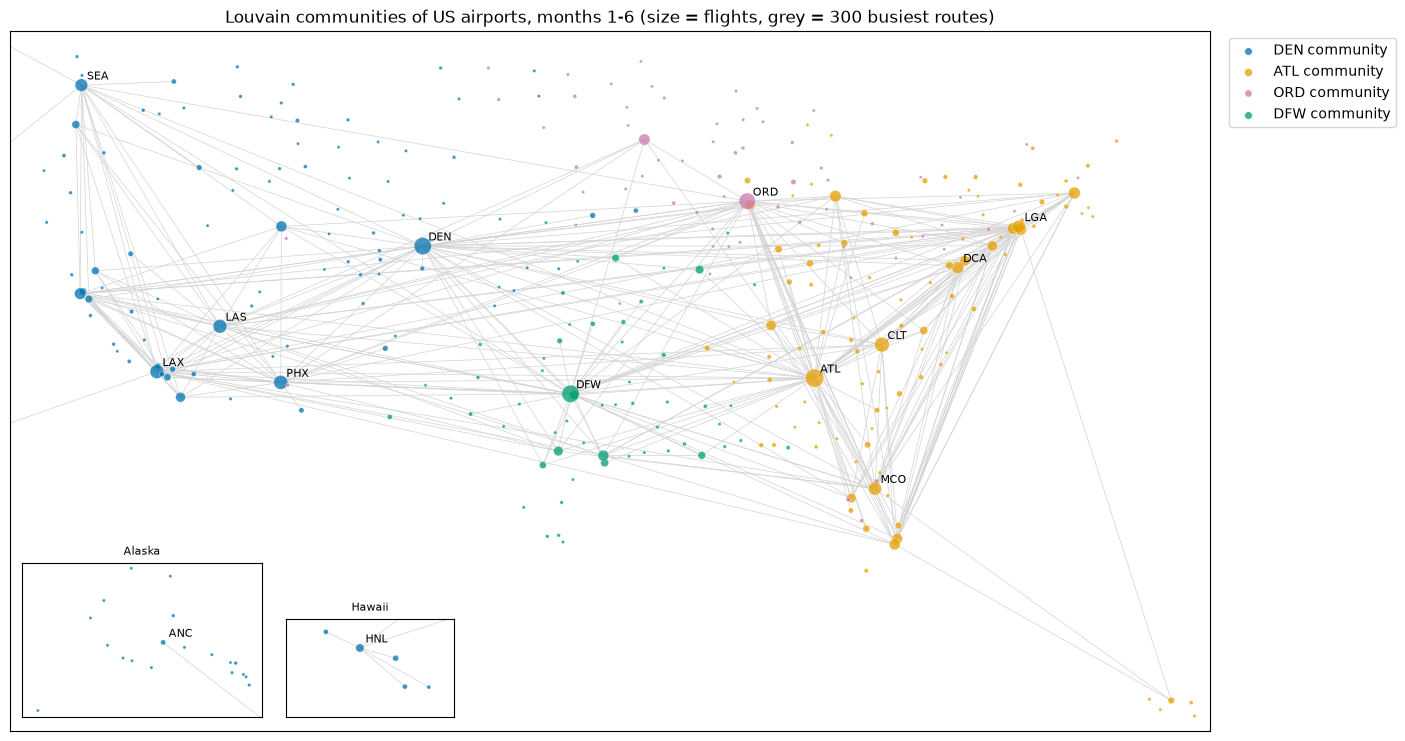

In [8]:
# coordinates only for drawing the map
airport_info = airportsdata.load("IATA")

missing = []
for airport in airport_list:
    if airport not in airport_info:
        missing.append(airport)
print("Airports with coordinates:", len(airport_list) - len(missing), "of", len(airport_list))
assert not missing, f"no coordinates for {missing}"

latitude = {}
longitude = {}
for airport in airport_list:
    latitude[airport] = airport_info[airport]["lat"]
    longitude[airport] = airport_info[airport]["lon"]


# a copy, so the coordinates do not end up in the airport table used by RQ3
map_airports = airports.copy()
map_airports["lat"] = map_airports["airport"].map(latitude)
map_airports["lon"] = map_airports["airport"].map(longitude)
map_airports["community_name"] = map_airports["louvain"].map(community_names).str.replace(" community", "")

# Okabe-Ito colours, readable for colour-blind readers 
community_colours = {"DEN": "#0072B2", "ATL": "#E69F00", "ORD": "#CC79A7", "DFW": "#009E73"}
assert set(map_airports["community_name"]) == set(community_colours), "a community has no colour"


# the 300 busiest routes, drawn in grey under the airports
routes = pd.DataFrame(list(graph.edges(data="flights")), columns=["airport_a", "airport_b", "flights"])
busiest_routes = routes.nlargest(300, "flights")


def draw_map(ax, lon_range, lat_range, label_airports):
    for route in busiest_routes.itertuples():
        ax.plot([longitude[route.airport_a], longitude[route.airport_b]],
                [latitude[route.airport_a], latitude[route.airport_b]],
                color="lightgrey", linewidth=0.5, zorder=1)
    for name, colour in community_colours.items():
        in_community = map_airports[map_airports["community_name"] == name]
        ax.scatter(in_community["lon"], in_community["lat"], s=5 + in_community["flights"] / 2000,
                   color=colour, alpha=0.75, edgecolor="white", linewidth=0.3, label=name + " community", zorder=2)
    for airport in label_airports:
        ax.annotate(airport, (longitude[airport], latitude[airport]), xytext=(4, 4),
                    textcoords="offset points", fontsize=8, zorder=3)
    ax.set_xlim(lon_range)
    ax.set_ylim(lat_range)
    ax.set_xticks([])
    ax.set_yticks([])


fig = plt.figure(figsize=(12, 7))
ax_main = fig.add_axes([0.0, 0.0, 1.0, 1.0])
draw_map(ax_main, (-126, -64), (17, 50), list(airports.nlargest(12, "flights")["airport"]))
ax_main.set_title("Louvain communities of US airports, months 1-6 (size = flights, grey = 300 busiest routes)")
ax_main.legend(loc="upper left", bbox_to_anchor=(1.01, 1), markerscale=0.6)

# Alaska and Hawaii as small insets (Guam and Saipan are not shown)
ax_alaska = fig.add_axes([0.01, 0.02, 0.2, 0.22])
draw_map(ax_alaska, (-180, -129), (51, 72), ["ANC"])
ax_alaska.set_title("Alaska", fontsize=8)
ax_hawaii = fig.add_axes([0.23, 0.02, 0.14, 0.14])
draw_map(ax_hawaii, (-161, -154), (18.5, 22.5), ["HNL"])
ax_hawaii.set_title("Hawaii", fontsize=8)

fig.savefig(FIGURES_DIR / "03_community_map.png", dpi=150, bbox_inches="tight")
plt.show()

On the map the four communities are clear regions: the West around DEN (with Alaska and Hawaii), the South-Central around DFW, the East around ATL, and a smaller Centre-North group around ORD and MSP. The few ORD community airports in Florida are Allegiant leisure airports, and Puerto Rico and the Virgin Islands belong to the East.

## 6. Airlines inside each community
We list the three largest airlines on the flights that stay inside each community. This shows whether a community follows an airline network as well as geography.

In [9]:
# January-June flights with the community at both ends
flights = load_flights(CLEAN_PARQUET, columns=["month", "origin", "dest", "op_unique_carrier"])
flights = flights[flights["month"] <= 6]
flights["c_origin"] = flights["origin"].astype(str).map(community_of)
flights["c_dest"] = flights["dest"].astype(str).map(community_of)


# only flights that stay inside one community, counted per airline
inside_flights = flights[flights["c_origin"] == flights["c_dest"]]
counts = inside_flights.groupby(["c_origin", "op_unique_carrier"], observed=True).size()
counts = counts.rename("flights").reset_index()
community_total = counts.groupby("c_origin")["flights"].transform("sum")
counts["share"] = counts["flights"] / community_total


# top 3 per community
counts = counts.sort_values(["c_origin", "flights"], ascending=[True, False])
top3 = counts.groupby("c_origin").head(3)
top3 = top3.rename(columns={"c_origin": "louvain", "op_unique_carrier": "airline"})
top3["louvain"] = top3["louvain"].astype(int).map(community_names)

display(top3.set_index(["louvain", "airline"]))
top3.to_csv(TABLES_DIR / "03_community_airlines.csv", index=False)

flights  share
louvain       airline                
DEN community WN        212096  0.301
              OO        177078  0.252
              AS         77766  0.111
ATL community DL        208020  0.187
              WN        169107  0.152
              AA        156683  0.141
ORD community OO         36502  0.499
              G4         15683  0.214
              MQ          6378  0.087
DFW community WN         56746  0.336
              MQ         49314  0.292
              AA         26246  0.156

No community belongs to a single airline, but the airlines differ. Southwest (WN) is the largest inside DEN and DFW, and Delta (DL) inside ATL, although Delta has only 19% there. The ORD community is the most airline-driven: half of its internal flights are SkyWest (OO), a regional carrier, and another 21% are Allegiant (G4), which fits the Florida leisure airports in this community.

## 7. Spectral clustering (comparison)
To check whether the communities depend on the method, we compare Louvain with spectral clustering, using raw, log and binary weights and k = 4, 5 and 6, the range of community counts Louvain finds over the 20 seeds.

In [10]:
# spectral clustering on a precomputed weight matrix, with a fixed seed
def run_spectral(weights, k):
    model = SpectralClustering(k, affinity="precomputed", assign_labels="cluster_qr", random_state=RANDOM_SEED)
    return model.fit_predict(weights)


# spectral with three weightings and several k, compared with Louvain on the same airports
def compare_spectral(network, nodes, louvain_labels, ks):
    adjacency = nx.to_numpy_array(network, nodelist=nodes, weight="flights")
    weight_versions = {
        "raw flights": adjacency,
        "log(1 + flights)": np.log1p(adjacency),
        "binary": (adjacency > 0).astype(float),
    }
    rows = []
    for weight_name, weights in weight_versions.items():
        for k in ks:
            labels = run_spectral(weights, k)
            group_sizes = sorted(np.bincount(labels), reverse=True)
            rows.append({
                "weights": weight_name,
                "k": k,
                "group_sizes": [int(size) for size in group_sizes],
                "modularity": modularity(network, groups_from_labels(labels, nodes), weight="flights"),
                "ARI_vs_louvain": adjusted_rand_score(louvain_labels, labels),
            })
    return pd.DataFrame(rows), weight_versions


spectral, weight_versions = compare_spectral(graph, airport_list, louvain, [4, 5, 6])
display(spectral)
spectral.to_csv(TABLES_DIR / "03_spectral_vs_louvain.csv", index=False)


# which airports are in the small groups?
labels_k4 = run_spectral(weight_versions["log(1 + flights)"], 4)
for group in groups_from_labels(labels_k4, airport_list):
    if len(group) < 50:
        print("Small group:", ", ".join(sorted(group)))

,weights,k,group_sizes,modularity,ARI_vs_louvain
0,raw flights,4,"[257, 65, 19, 2]",0.181,0.126
1,raw flights,5,"[259, 58, 20, 4, 2]",0.176,0.103
2,raw flights,6,"[168, 148, 13, 7, 5, 2]",0.237,0.342
3,log(1 + flights),4,"[317, 15, 6, 5]",0.015,-0.019
4,log(1 + flights),5,"[181, 141, 13, 6, 2]",0.228,0.375
5,log(1 + flights),6,"[177, 93, 45, 19, 6, 3]",0.183,0.308
6,binary,4,"[318, 13, 7, 5]",0.011,-0.019
7,binary,5,"[184, 137, 12, 7, 3]",0.217,0.370
8,binary,6,"[185, 137, 11, 4, 4, 2]",0.218,0.370


Small group: GUM, HNL, ITO, PPG, SPN
Small group: GST, JNU, KTN, PSG, SIT, WRG
Small group: ADK, ADQ, AKN, ANC, BET, BRW, CDV, DLG, FAI, KOA, OGG, OME, OTZ, SCC, YAK


Spectral clustering spends its first groups on Alaska, Hawaii and the islands, which hardly connect to the rest. For a fairer comparison we run it again on the mainland only (the 48 contiguous states and DC) and compare it with the Louvain communities of the same airports.

In [11]:
# state of every airport (from departing and arriving flights); each airport has one state,
# so the unique (airport, state) pairs are enough and much faster than looping over all flights
states = load_flights(CLEAN_PARQUET, columns=["origin", "dest", "origin_state_nm", "dest_state_nm"])
state_of = {}
for side in ["origin", "dest"]:
    pairs = states[[side, f"{side}_state_nm"]].drop_duplicates()
    state_of.update(zip(pairs[side].astype(str), pairs[f"{side}_state_nm"].astype(str)))


# mainland = the 48 contiguous states and DC
not_mainland = ["Alaska", "Hawaii", "Puerto Rico", "U.S. Virgin Islands",
                "U.S. Pacific Trust Territories and Possessions"]
mainland_airports = []
for airport in airport_list:
    if state_of[airport] not in not_mainland:
        mainland_airports.append(airport)
print("Mainland airports:", len(mainland_airports), "of", len(airport_list))

mainland_graph = graph.subgraph(mainland_airports).copy()
print("Mainland graph connected:", nx.is_connected(mainland_graph))


# Louvain labels of the same airports, for the comparison
louvain_mainland = np.array([community_of[airport] for airport in mainland_airports])

mainland_spectral, _ = compare_spectral(mainland_graph, mainland_airports, louvain_mainland, [3, 4, 5])
display(mainland_spectral)
mainland_spectral.to_csv(TABLES_DIR / "03_spectral_mainland.csv", index=False)

louvain_mainland_groups = groups_from_labels(louvain_mainland, mainland_airports)
mainland_modularity = modularity(mainland_graph, louvain_mainland_groups, weight="flights")
print("Louvain on the same airports, modularity:", round(mainland_modularity, 3))

Mainland airports: 311 of 343
Mainland graph connected: True


,weights,k,group_sizes,modularity,ARI_vs_louvain
0,raw flights,3,"[158, 149, 4]",0.223,0.392
1,raw flights,4,"[158, 110, 41, 2]",0.190,0.436
2,raw flights,5,"[128, 116, 58, 7, 2]",0.195,0.482
3,log(1 + flights),3,"[168, 81, 62]",0.026,0.113
4,log(1 + flights),4,"[149, 114, 33, 15]",0.097,0.226
5,log(1 + flights),5,"[139, 89, 66, 15, 2]",0.067,0.139
6,binary,3,"[179, 73, 59]",0.131,0.384
7,binary,4,"[177, 66, 59, 9]",0.152,0.322
8,binary,5,"[155, 107, 26, 16, 7]",0.063,0.175


Louvain on the same airports, modularity: 0.24


On all 343 airports, spectral clustering first separates Hawaii, Alaska and the Pacific islands. With log or binary weights and k = 4 the whole mainland stays in one group (317–318 airports, ARI about 0 with Louvain), and the mainland only splits from k = 5 (ARI up to 0.375). With raw weights it splits the mainland earlier but agrees little with Louvain (ARI 0.10–0.34).

On the 311 mainland airports, raw weights agree more with Louvain (ARI 0.39–0.48 for k = 3–5), but the modularity (0.19–0.22) stays below Louvain's on the same airports (0.24). The log and binary versions agree less (ARI 0.11–0.38). Spectral clustering depends a lot on the weights and on k, even without the islands, so we keep Louvain as the main method.

## 8. Bridge airports (betweenness)
Betweenness counts how many shortest paths pass through an airport. With `distance = 1 / flights` busy hubs are favoured, so we also compute it with hop count and compare the two top 15 lists.

[betweenness] runtime: 3.83 s | peak memory (Python/pandas): 0.3 MB | peak memory (pyarrow pool): 216.1 MB


,rank,airport_weighted,betweenness_weighted,airport_hops,betweenness_hops
0,1,DEN,0.351,DFW,0.184
1,2,ATL,0.331,DEN,0.178
2,3,DFW,0.223,ORD,0.106
3,4,ORD,0.197,ATL,0.090
4,5,SEA,0.143,MSP,0.076
5,6,LAX,0.090,ANC,0.066
6,7,MSP,0.075,SEA,0.048
7,8,SLC,0.065,DTW,0.047
8,9,ANC,0.058,LAS,0.045
9,10,PHX,0.047,SLC,0.042


Spearman correlation between the two versions: 0.569
Airports in both top 15: 13


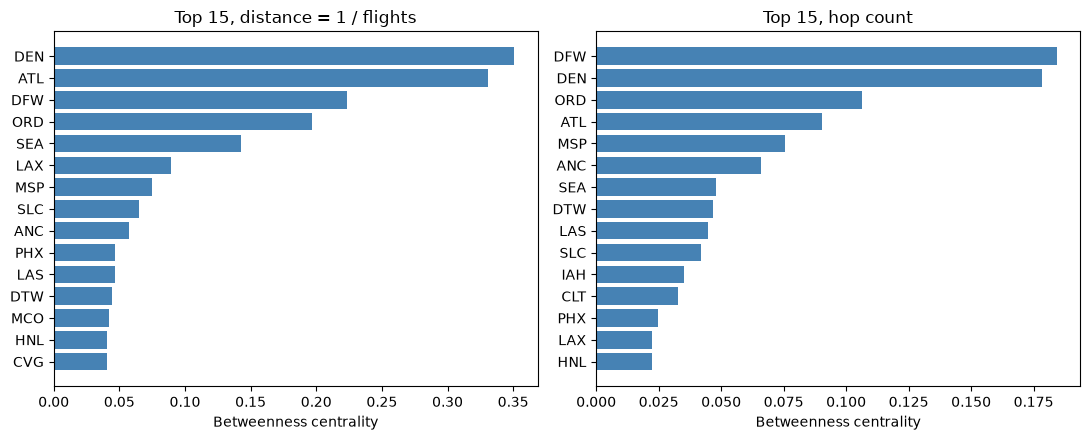

In [12]:
# betweenness with distance = 1 / flights and with hop count
with track("betweenness", airports=graph.number_of_nodes()):
    airports["betweenness"] = airports["airport"].map(nx.betweenness_centrality(graph, weight="distance"))
    airports["betweenness_hops"] = airports["airport"].map(nx.betweenness_centrality(graph))


# the two top 15 lists side by side
top_weighted = airports.nlargest(15, "betweenness").reset_index(drop=True)
top_hops = airports.nlargest(15, "betweenness_hops").reset_index(drop=True)
top = pd.DataFrame({
    "rank": range(1, 16),
    "airport_weighted": top_weighted["airport"],
    "betweenness_weighted": top_weighted["betweenness"],
    "airport_hops": top_hops["airport"],
    "betweenness_hops": top_hops["betweenness_hops"],
})
display(top)
top.to_csv(TABLES_DIR / "03_betweenness_top15.csv", index=False)

rank_correlation = spearmanr(airports["betweenness"], airports["betweenness_hops"]).statistic
in_both = set(top_weighted["airport"]) & set(top_hops["airport"])
print("Spearman correlation between the two versions:", round(rank_correlation, 3))
print("Airports in both top 15:", len(in_both))


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
panels = [(axes[0], "betweenness", "Top 15, distance = 1 / flights"),
          (axes[1], "betweenness_hops", "Top 15, hop count")]
for ax, column, title in panels:
    top_15 = airports.nlargest(15, column)
    ax.barh(top_15["airport"][::-1], top_15[column][::-1], color="steelblue")
    ax.set_xlabel("Betweenness centrality")
    ax.set_title(title)
save_fig(fig, "top_betweenness")

## 9. Scalability: approximate betweenness
Exact betweenness gets slow on large networks. networkx can estimate it from k sampled airports, so we check the runtime and how many of the exact top 15 the estimate finds. The pyarrow memory in the printout is the peak since the kernel started, not of this step.

In [13]:
# exact betweenness, then estimates from k sampled airports
exact_top15 = set(top_weighted["airport"])

with track("betweenness_exact", airports=graph.number_of_nodes()) as stats:
    nx.betweenness_centrality(graph, weight="distance")
scalability_rows = [{"k_samples": "exact (343)", "runtime_s": stats["runtime_s"], "top15_recovered": 15}]

for k in [25, 50, 100, 200]:
    with track("betweenness_approx", k=k) as stats:
        approx = nx.betweenness_centrality(graph, k=k, weight="distance", seed=RANDOM_SEED)
    approx_top15 = set(pd.Series(approx).nlargest(15).index)
    recovered = len(approx_top15 & exact_top15)
    scalability_rows.append({"k_samples": str(k), "runtime_s": stats["runtime_s"], "top15_recovered": recovered})

scalability = pd.DataFrame(scalability_rows)
display(scalability)
scalability.to_csv(TABLES_DIR / "03_betweenness_scalability.csv", index=False)

[betweenness_exact] runtime: 2.58 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB
[betweenness_approx] runtime: 0.18 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 0.38 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 0.80 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


[betweenness_approx] runtime: 1.60 s | peak memory (Python/pandas): 0.2 MB | peak memory (pyarrow pool): 216.1 MB


,k_samples,runtime_s,top15_recovered
0,exact (343),2.575,15
1,25,0.182,11
2,50,0.381,14
3,100,0.797,13
4,200,1.596,14


With 50 sampled airports the estimate is about 5–7 times faster in our runs (exact timings depend on the machine) and still finds 14 of the top 15 airports. The sample is random, so more samples do not always help: 100 samples find 13. For a network this small the exact version is fine.

## 10. Delays by community
Do communities differ in delays? We use completed flights from January–June and give each flight the community of its origin airport. A flight is late if it arrives 15+ minutes late. With millions of flights the p-value is always about 0, so we look at the effect size, epsilon-squared = (H − k + 1) / (n − k), with k groups and n observations. This is the same formula as in RQ1 (0.01 small, 0.06 medium, 0.14 large).

In [14]:
delay_flights = load_flights(CLEAN_PARQUET, columns=["month", "origin", "dest", "op_unique_carrier", "status", "arr_delay", "dep_delay"])
delay_flights = delay_flights[(delay_flights["month"] <= 6) & (delay_flights["status"] == "completed")]
delay_flights["origin_community"] = delay_flights["origin"].astype(str).map(community_of)
delay_flights["dest_community"] = delay_flights["dest"].astype(str).map(community_of)
delay_flights["inside"] = delay_flights["origin_community"] == delay_flights["dest_community"]


def delay_summary(group, arr_delay):
    return {
        "group": group,
        "flights": len(arr_delay),
        "late_share": float((arr_delay >= 15).mean()),
        "median_arr_delay": float(arr_delay.median()),
        "p90_arr_delay": float(arr_delay.quantile(0.9)),
    }


# one row per community, then flights inside one community vs between communities
delay_rows = []
for community in sorted(community_names):
    in_community = delay_flights[delay_flights["origin_community"] == community]
    delay_rows.append(delay_summary(community_names[community], in_community["arr_delay"]))
delay_rows.append(delay_summary("inside one community", delay_flights.loc[delay_flights["inside"], "arr_delay"]))
delay_rows.append(delay_summary("between communities", delay_flights.loc[~delay_flights["inside"], "arr_delay"]))

delays_by_community = pd.DataFrame(delay_rows)
display(delays_by_community)
delays_by_community.to_csv(TABLES_DIR / "03_delays_by_community.csv", index=False)

,group,flights,late_share,median_arr_delay,p90_arr_delay
0,DEN community,1055398,0.207,-5.000,39.000
1,ATL community,1570829,0.219,-6.000,47.000
2,ORD community,272076,0.223,-7.000,52.000
3,DFW community,505169,0.249,-4.000,56.000
4,inside one community,2021798,0.211,-6.000,44.000
5,between communities,1381674,0.233,-5.000,49.000


Late share, all flights: 0.22


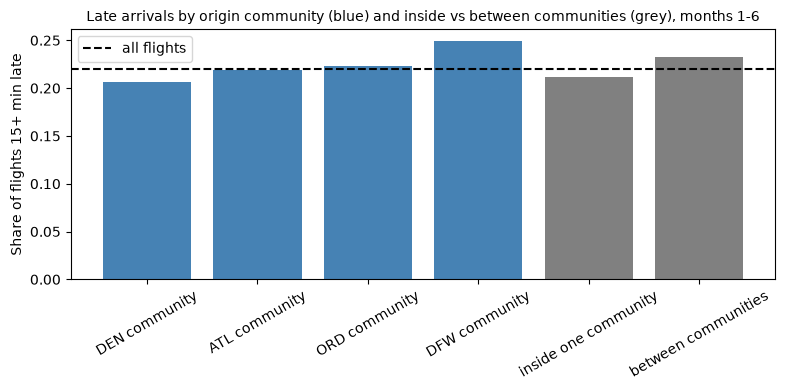

In [15]:
overall_late_share = float((delay_flights["arr_delay"] >= 15).mean())
print("Late share, all flights:", round(overall_late_share, 3))

# communities in blue, inside/between in grey
bar_colours = []
for group in delays_by_community["group"]:
    if group in ["inside one community", "between communities"]:
        bar_colours.append("grey")
    else:
        bar_colours.append("steelblue")


fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(delays_by_community["group"], delays_by_community["late_share"], color=bar_colours)
ax.axhline(overall_late_share, color="black", linestyle="--", label="all flights")
ax.set_ylabel("Share of flights 15+ min late")
ax.set_title("Late arrivals by origin community (blue) and inside vs between communities (grey), months 1-6")
ax.title.set_fontsize(10)
ax.tick_params(axis="x", rotation=30)
ax.legend()
save_fig(fig, "delays_by_community")

In [16]:
# Kruskal-Wallis on the arrival delays of the four origin communities
delay_groups = []
for community in sorted(community_names):
    in_community = delay_flights["origin_community"] == community
    delay_groups.append(delay_flights.loc[in_community, "arr_delay"])
kw_result = kruskal(*delay_groups)

n_flights = len(delay_flights)
n_groups = len(delay_groups)
epsilon_squared = (kw_result.statistic - n_groups + 1) / (n_flights - n_groups)

print("Flights:", n_flights)
print("Kruskal-Wallis H:", round(kw_result.statistic, 1))
print("p-value:", kw_result.pvalue)
print("Epsilon-squared:", round(epsilon_squared, 4))

Flights: 3403472
Kruskal-Wallis H: 11165.5
p-value: 0.0
Epsilon-squared: 0.0033


Flights from the same airport are not independent (same weather, same congestion), so we also run the test per airport: each airport counts once, with the share of its departing flights that arrive 15+ minutes late.

In [17]:
origin = delay_flights["origin"].astype(str)
late_arrival = delay_flights["arr_delay"] >= 15
airports["late_arrival_share"] = airports["airport"].map(late_arrival.groupby(origin).mean())
airports["departing_flights"] = airports["airport"].map(origin.value_counts())


def airport_level_kruskal(airport_table):
    # Kruskal-Wallis with each airport counted once (its late arrival share), plus epsilon-squared
    groups = [airport_table.loc[airport_table["louvain"] == community, "late_arrival_share"].dropna()
              for community in sorted(community_names)]
    result = kruskal(*groups)
    n_tested = sum(len(group) for group in groups)
    epsilon_sq = (result.statistic - len(groups) + 1) / (n_tested - len(groups))
    return result, epsilon_sq, n_tested, groups


airport_kw, airport_epsilon_squared, n_airports_tested, airport_groups = airport_level_kruskal(airports)
print("Airports tested:", n_airports_tested)
print("Kruskal-Wallis H:", round(airport_kw.statistic, 2))
print("p-value:", airport_kw.pvalue)
print("Epsilon-squared:", round(airport_epsilon_squared, 4))

for community, group in zip(sorted(community_names), airport_groups):
    print(community_names[community], "- median airport late share:", round(group.median(), 3))

Airports tested: 343
Kruskal-Wallis H: 40.52
p-value: 8.279179630239086e-09
Epsilon-squared: 0.1107
DEN community - median airport late share: 0.167
ATL community - median airport late share: 0.195
ORD community - median airport late share: 0.2
DFW community - median airport late share: 0.201


Small airports have few departures, so their late shares are noisy. We repeat the airport-level test with only the airports that have at least 500 departures, to check that small airports do not drive the effect.

In [18]:
busy_airports = airports[airports["departing_flights"] >= 500]
busy_kw, busy_epsilon_squared, n_busy_tested, busy_groups = airport_level_kruskal(busy_airports)

print("Airports with >= 500 departures:", n_busy_tested)
print("Kruskal-Wallis H:", round(busy_kw.statistic, 2))
print("p-value:", busy_kw.pvalue)
print("Epsilon-squared:", round(busy_epsilon_squared, 4))

for community, group in zip(sorted(community_names), busy_groups):
    print(community_names[community], "-", len(group), "airports, median late share:", round(group.median(), 3))

Airports with >= 500 departures: 233
Kruskal-Wallis H: 25.96
p-value: 9.719356854737422e-06
Epsilon-squared: 0.1003
DEN community - 70 airports, median late share: 0.181
ATL community - 86 airports, median late share: 0.197
ORD community - 31 airports, median late share: 0.201
DFW community - 46 airports, median late share: 0.202


Are bridge airports more delayed? Here we use late departures (15+ minutes), because a departure delay says more about the airport itself than an arrival delay.

In [19]:
late_departure = delay_flights["dep_delay"] >= 15
origin_airport = delay_flights["origin"].astype(str)
airports["late_departure_share"] = airports["airport"].map(late_departure.groupby(origin_airport).mean())


def rho(table, column):
    # Spearman correlation between a betweenness column and the late departure share
    return round(spearmanr(table[column], table["late_departure_share"]).statistic, 3)


print("Spearman, betweenness vs late departures:", rho(airports, "betweenness"))
print("Spearman, betweenness (hops) vs late departures:", rho(airports, "betweenness_hops"))


# same thing without the small airports (noisy shares); busy_airports was made
# before late_departure_share existed, so we select the busy airports again
busy = airports[airports["departing_flights"] >= 500]
print("Airports with >= 500 departures:", len(busy))
print("Spearman (>= 500), betweenness vs late departures:", rho(busy, "betweenness"))
print("Spearman (>= 500), betweenness (hops) vs late departures:", rho(busy, "betweenness_hops"))

Spearman, betweenness vs late departures: 0.196
Spearman, betweenness (hops) vs late departures: 0.303
Airports with >= 500 departures: 233
Spearman (>= 500), betweenness vs late departures: 0.234
Spearman (>= 500), betweenness (hops) vs late departures: 0.272


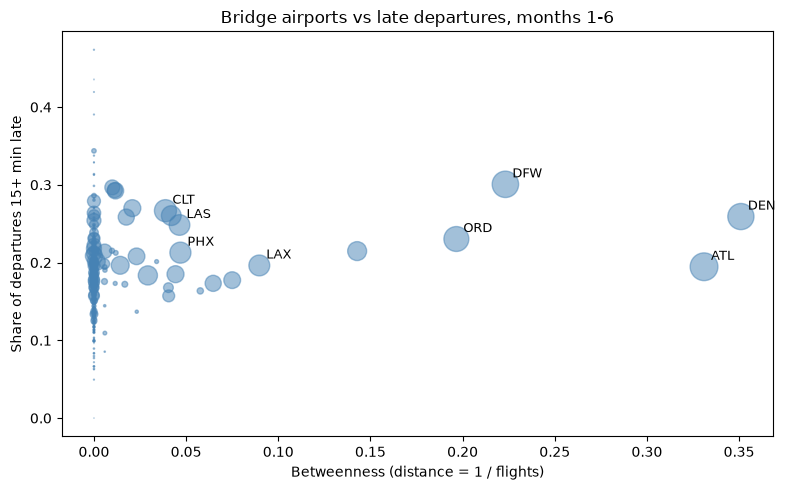

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
point_sizes = airports["flights"] / airports["flights"].max() * 400
ax.scatter(airports["betweenness"], airports["late_departure_share"], s=point_sizes, alpha=0.5, color="steelblue")

# label the 8 busiest airports
busiest = airports.nlargest(8, "flights")
for row in busiest.itertuples():
    ax.annotate(row.airport, (row.betweenness, row.late_departure_share),
                textcoords="offset points", xytext=(5, 5), fontsize=9)

ax.set_xlabel("Betweenness (distance = 1 / flights)")
ax.set_ylabel("Share of departures 15+ min late")
ax.set_title("Bridge airports vs late departures, months 1-6")
save_fig(fig, "betweenness_vs_delay")

ATL is a big bridge with few late departures. Is that because of its main airline? For the four largest hubs we compare the late departure share of the main airline with that of the other airlines at the same airport.

In [21]:
# late departures at the four largest hubs: main airline vs the other airlines
airlines = load_flights(CLEAN_PARQUET, columns=["month", "origin", "op_unique_carrier", "status", "dep_delay"])
airlines = airlines[(airlines["month"] <= 6) & (airlines["status"] == "completed")]
airlines["late_departure"] = airlines["dep_delay"] >= 15
print("Late departure share, all flights:", round(airlines["late_departure"].mean(), 3))

hub_rows = []
for hub in ["ATL", "DEN", "DFW", "ORD"]:
    at_hub = airlines[airlines["origin"].astype(str) == hub]
    main_airline = at_hub["op_unique_carrier"].value_counts().index[0]
    is_main = at_hub["op_unique_carrier"] == main_airline
    main_everywhere = airlines["op_unique_carrier"] == main_airline
    hub_rows.append({
        "hub": hub,
        "late_departure_share": at_hub["late_departure"].mean(),
        "main_airline": main_airline,
        "main_airline_share_of_departures": is_main.mean(),
        "main_airline_late_share": at_hub.loc[is_main, "late_departure"].mean(),
        "other_airlines_late_share": at_hub.loc[~is_main, "late_departure"].mean(),
        "main_airline_late_share_everywhere": airlines.loc[main_everywhere, "late_departure"].mean(),
    })

hub_airlines = pd.DataFrame(hub_rows)
display(hub_airlines)
hub_airlines.to_csv(TABLES_DIR / "03_hub_main_airline.csv", index=False)

Late departure share, all flights: 0.217


,hub,late_departure_share,main_airline,main_airline_share_of_departures,main_airline_late_share,other_airlines_late_share,main_airline_late_share_everywhere
0,ATL,0.195,DL,0.662,0.174,0.235,0.169
1,DEN,0.259,WN,0.333,0.341,0.218,0.253
2,DFW,0.301,AA,0.542,0.366,0.224,0.272
3,ORD,0.230,UA,0.320,0.220,0.235,0.202


Per flight, the communities differ little: 20.7% of flights are late in the DEN community and 24.9% in DFW (22.0% overall). Flights between communities are late a bit more often than flights inside one (23.3% vs 21.1%), but they are also longer (median 1,050 vs 494 miles) and pass through hubs, which can explain part of the gap. The Kruskal–Wallis test compares the arrival-delay distributions of the four communities; its effect size is tiny (0.003), so the community explains little of a single flight's delay.

Per airport the effect is medium (0.11): the typical DEN-community airport has 16.7% late flights, against about 20% in the others. With only the 233 airports that have 500+ departures it is 0.10, so small airports do not drive it. Bridge airports have slightly more late departures (Spearman 0.20–0.30, and 0.23–0.27 for airports with 500+ departures). ATL is the exception: a top bridge with only 19.5% late departures. Delta runs 66% of ATL departures with only 17.4% late (16.9% across all its airports), while the other airlines at ATL are at 23.5%. DFW is the opposite: American runs 54% of its departures, and 36.6% of them leave late.

## 11. Link with RQ1: route clusters inside and between communities
RQ1 groups route + airline pairs by their schedule into 7 clusters (January–June). Here we join those clusters to the flights and check two things: whether some route clusters cross communities more often, and whether the gap between inside and between-community flights is the same in every cluster. We use the same flights as above (completed, January–June) and leave out flights on routes without an RQ1 cluster (fewer than 30 flights).

In [22]:
# RQ1 route clusters (notebook 02/02b) joined to the flights
route_clusters = pd.read_csv(TABLES_DIR / "rq1_route_clusters_jan_jun.csv")
cluster_names = pd.read_csv(TABLES_DIR / "02b_cluster_profiles.csv").set_index("cluster")["name"]

link = delay_flights[["origin", "dest", "op_unique_carrier", "inside", "arr_delay"]].copy()
for column in ["origin", "dest", "op_unique_carrier"]:
    link[column] = link[column].astype(str)
link = link.merge(route_clusters, on=["origin", "dest", "op_unique_carrier"], how="left", validate="many_to_one")
print(f"Flights with an RQ1 cluster: {link['route_cluster'].notna().mean():.1%}")

link = link.dropna(subset=["route_cluster"])
link["late"] = link["arr_delay"] >= 15
link["route_cluster"] = link["route_cluster"].astype(int).map(cluster_names)


def link_row(group):
    inside = group[group["inside"]]
    between = group[~group["inside"]]
    return pd.Series({
        "flights": len(group),
        "share_between_communities": 1 - group["inside"].mean(),
        "late_share": group["late"].mean(),
        "late_share_inside": inside["late"].mean(),
        "late_share_between": between["late"].mean(),
        "gap_between_minus_inside": between["late"].mean() - inside["late"].mean(),
    })


rq1_rq2_link = link.groupby("route_cluster").apply(link_row).sort_values("flights", ascending=False)
rq1_rq2_link.loc["all clusters"] = link_row(link)
display(rq1_rq2_link.round(3))
rq1_rq2_link.to_csv(TABLES_DIR / "03_rq1_rq2_link.csv")

Flights with an RQ1 cluster: 99.2%


,flights,share_between_communities,late_share,late_share_inside,late_share_between,gap_between_minus_inside
route_cluster,,,,,,
Busy all-day,"2,325,602.000",0.326,0.219,0.212,0.234,0.022
Long-haul,"339,227.000",0.859,0.221,0.204,0.224,0.020
Morning,"246,657.000",0.431,0.173,0.167,0.182,0.015
Afternoon,"234,018.000",0.452,0.229,0.218,0.242,0.024
Evening/night,"187,813.000",0.451,0.270,0.250,0.293,0.043
"Infrequent, weekend-leaning","38,864.000",0.497,0.229,0.216,0.243,0.028
Weekend-only,"5,399.000",0.444,0.267,0.271,0.263,-0.008
all clusters,"3,377,580.000",0.405,0.220,0.211,0.233,0.022


99.2% of the flights have an RQ1 cluster. Long-haul routes cross communities most often (86% of their flights) and busy all-day routes least (33%). In 6 of the 7 clusters, flights between communities are late more often than flights inside one, by 1.5 to 4.3 points (2.2 overall). The gap is largest for evening/night routes (25.0% vs 29.3%) and is also there for long-haul routes (2.0 points), so it does not only come from between-community flights being longer. Only the very small weekend-only cluster (5,399 flights) shows no gap. The two results therefore carry partly different information: the schedule sets the level of delay (17% for morning routes, 27% for evening/night) and crossing communities adds a small extra risk.

## 12. Are the communities stable over time?
RQ3 uses the January–June communities for all test months, so we check whether they still hold in July–December. We run the same 20-seed Louvain on July–December (only airports present in both periods) and compare the two with ARI. For reference, in January–June the ARI of each seed's partition with the best run was 0.85 on average (minimum 0.65).

In [23]:
all_flights = load_flights(CLEAN_PARQUET, columns=["month", "origin", "dest"])
graph_late_full = build_graph(build_edges(all_flights, months=range(7, 13)))

# airports in both periods
common_airports = sorted(set(graph) & set(graph_late_full))
graph_late = graph_late_full.subgraph(common_airports).copy()
print("Airports in both periods:", len(common_airports))
print("Only in months 1-6:", ", ".join(sorted(set(graph) - set(graph_late_full))))
print("Only in months 7-12:", ", ".join(sorted(set(graph_late_full) - set(graph))))

# same procedure as before: 20 seeds, keep the best (best_louvain from src/network.py)
best_late_sorted, late_modularity = best_louvain(graph_late)
late_labels = community_labels(best_late_sorted, common_airports)
early_labels = [community_of[airport] for airport in common_airports]

period_ari = adjusted_rand_score(early_labels, late_labels)
print("Communities in months 7-12:", len(best_late_sorted))
print("Modularity in months 7-12:", round(late_modularity, 3))
print("ARI months 1-6 vs 7-12:", round(period_ari, 3))
print("ARI of each seed vs the best run, months 1-6, mean:", round(seed_table["ARI_vs_best"].mean(), 3))
print("ARI of each seed vs the best run, months 1-6, min:", round(seed_table["ARI_vs_best"].min(), 3))

Airports in both periods: 341
Only in months 1-6: CNY, VEL
Only in months 7-12: EAR, EAU, EWN, MGW, PQI


Communities in months 7-12: 4
Modularity in months 7-12: 0.255
ARI months 1-6 vs 7-12: 0.735
ARI of each seed vs the best run, months 1-6, mean: 0.847
ARI of each seed vs the best run, months 1-6, min: 0.645


In [24]:
# where do the airports of each community go in months 7-12?
# the months 7-12 communities are named after their busiest airport, like in months 1-6
late_flights_per_airport = dict(graph_late.degree(weight="flights"))
late_community_names = {}
for number, community in enumerate(best_late_sorted):
    busiest_airport = max(community, key=late_flights_per_airport.get)
    late_community_names[number] = busiest_airport + " community"

early_names = [community_names[label] for label in early_labels]
late_names = [late_community_names[label] for label in late_labels]
crosstab = pd.crosstab(pd.Series(early_names, name="months 1-6"), pd.Series(late_names, name="months 7-12"))
display(crosstab)
crosstab.to_csv(TABLES_DIR / "03_community_stability.csv")

months 7-12,ATL community,DEN community,DFW community,MSP community
months 1-6,,,,
ATL community,100,0,0,0
DEN community,0,118,0,0
DFW community,7,0,51,0
ORD community,36,3,1,25


The ARI between the two periods is 0.74, a bit below the agreement between seeds within January–June (mean 0.85, minimum 0.65), so the change over time is only slightly larger than Louvain's own randomness. The ATL and DEN communities stay the same and DFW keeps 51 of its 58 airports, but the ORD community mostly falls apart: 36 of its 65 airports join the East, and the remaining Centre-North group is centred on MSP. Using the January–June communities in RQ3 is fine, but the ORD community is the least reliable one.

## 13. Output for RQ3
One row per airport with its community, betweenness, degree, flights and delay shares (January–June).

In [25]:
# RQ3 reads this file, so check it before saving
assert len(airports) == 343, "expected 343 airports"
assert airports["louvain"].nunique() == 4, "expected 4 Louvain communities"

airports.to_csv(TABLES_DIR / "03_airports.csv", index=False)
print("Number of airports saved:", len(airports))

Number of airports saved: 343


## Limitations
- Louvain depends on the seed: 4 to 6 communities over 20 seeds (mean ARI 0.85). We keep the run with the highest modularity.
- We use only January–June on purpose, so RQ2 never sees the RQ3 test months. Because of this, EAR, EAU, EWN, MGW and PQI (flights only after June) have no community.
- The communities change a little over time (ARI 0.74 with July–December), mostly the ORD community.
- Spectral clustering mainly separates Hawaii and Alaska and depends a lot on k and the weights, also on the mainland only, so we use it only as a comparison.
- Flights are not independent (same airport, same day), so the flight-level test is too optimistic. The airport-level test helps, but we still read effect sizes rather than p-values.